# RefCOCO exploratory data analysis

Pair counts, modality completeness, text and mask properties, and what each measurement implies
for the encoders and the fusion. Figures are written to `results/eda/`.

In [1]:
import sys
import collections
import random

sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from pycocotools import mask as mask_utils

from shared import io as shared_io
from shared.figures import COLOURS, save
from src.data import build_vocabulary, load_refs, prepare_annotations
from src.utils import load_config, resolve_path

config = load_config(resolve_path("configs/base.yaml"))
refs, instances = load_refs(prepare_annotations(config))
annotations = {a["id"]: a for a in instances["annotations"]}
images = {i["id"]: i for i in instances["images"]}
categories = {c["id"]: c["name"] for c in instances["categories"]}
IMAGE_DIR = resolve_path("data/images")
EDA = resolve_path("results/eda")
SPLITS = ("train", "val", "testA", "testB")

## Dataset description

RefCOCO pairs a photograph with short expressions, each naming one annotated object in it. The
expressions were collected in a two-player game: one player described an object until the other
could click it, which rewarded the shortest description that still disambiguated.

In [2]:
expressions = [s for r in refs for s in r["sentences"]]
print(f"{len(images):,} images, {len(refs):,} referred objects, {len(expressions):,} expressions")
print(f"{len(expressions) / len(refs):.2f} expressions per object")
print(f"{len(instances['annotations']):,} COCO instances annotated across those images")

rows = []
for name in SPLITS:
    members = [r for r in refs if r["split"] == name]
    rows.append((name, len({r["image_id"] for r in members}), len(members),
                 sum(len(r["sentences"]) for r in members)))
print(f"\n{'split':<8}{'images':>8}{'objects':>9}{'expressions':>13}")
for name, i, o, e in rows:
    print(f"{name:<8}{i:>8,}{o:>9,}{e:>13,}")

19,994 images, 50,000 referred objects, 142,210 expressions
2.84 expressions per object
196,771 COCO instances annotated across those images

split     images  objects  expressions
train     16,994   42,404      120,624
val        1,500    3,811       10,834
testA        750    1,975        5,657
testB        750    1,810        5,095


## Modality completeness

Section 29.2 asks for a missing-modality policy where one applies.

In [3]:
missing = {
    "expression": sum(1 for r in refs if not r["sentences"]),
    "image": sum(1 for r in refs if r["image_id"] not in images),
    "mask": sum(1 for r in refs if r["ann_id"] not in annotations),
}
print({k: f"{v} ({v / len(refs):.2%})" for k, v in missing.items()})

{'expression': '0 (0.00%)', 'image': '0 (0.00%)', 'mask': '0 (0.00%)'}


Every pair carries both modalities and a mask, so a missing-modality path would never run and
the report says so rather than inventing one.

## Distractors within a category

No referred object is the only instance of its category in its image: the game only used images
holding at least two. This bounds what a model that never reads the expression can reach.

a model that finds the right category but guesses among its instances reaches 30.5%


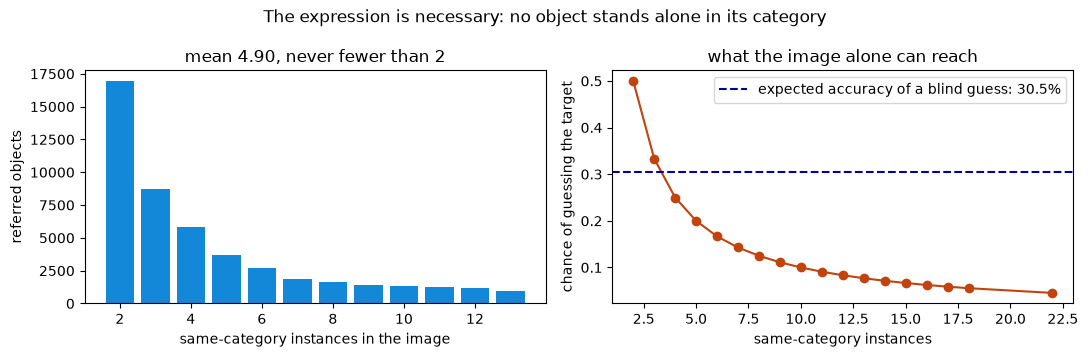

In [4]:
per_image_category = collections.Counter(
    (a["image_id"], a["category_id"]) for a in instances["annotations"]
)
distractors = [per_image_category[(r["image_id"], r["category_id"])] for r in refs]
counts = collections.Counter(distractors)
ceiling = sum(1 / n for n in distractors) / len(distractors)

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
keys = sorted(counts)[:12]
left.bar(keys, [counts[k] for k in keys], color=COLOURS[0])
left.set_xlabel("same-category instances in the image")
left.set_ylabel("referred objects")
left.set_title(f"mean {np.mean(distractors):.2f}, never fewer than {min(distractors)}")

order = sorted(set(distractors))
right.plot(order, [1 / n for n in order], marker="o", color=COLOURS[2])
right.axhline(ceiling, linestyle="--", color=COLOURS[1],
              label=f"expected accuracy of a blind guess: {ceiling:.1%}")
right.set_xlabel("same-category instances")
right.set_ylabel("chance of guessing the target")
right.legend()
right.set_title("what the image alone can reach")
fig.suptitle("The expression is necessary: no object stands alone in its category")
save(fig, EDA / "distractors", close=False)
print(f"a model that finds the right category but guesses among its instances reaches {ceiling:.1%}")

The expression is therefore the only signal separating the target from its distractors. Pooling
it into one vector, as the simple-fusion baseline does, asks the vision branch to find every
instance and then re-weight them; cross-attention lets a token address a position directly. The
ablation measures the difference.

## Split composition

testA and testB were built to hold people and non-people, so they are not two samples of one
distribution.

train  person  49.6%   categories  78
val    person  50.3%   categories  66
testA  person  93.0%   categories  31
testB  person   0.0%   categories  64


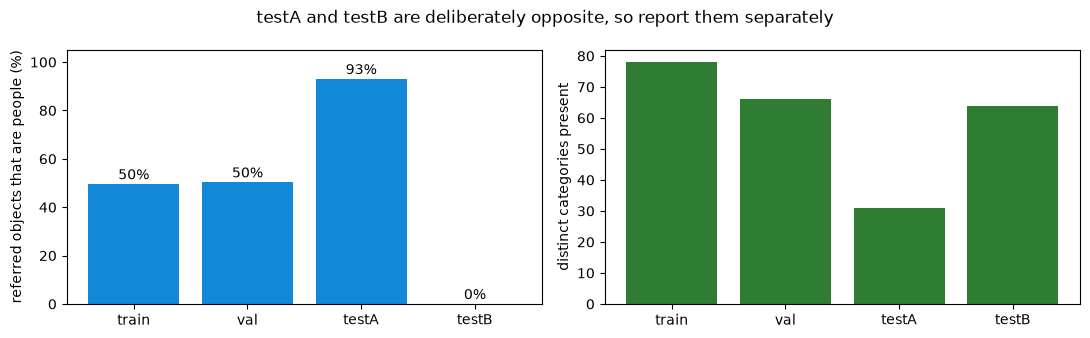

In [5]:
split_person, split_categories = {}, {}
for name in SPLITS:
    members = [r for r in refs if r["split"] == name]
    split_person[name] = sum(
        1 for r in members if categories[r["category_id"]] == "person") / len(members)
    split_categories[name] = len({r["category_id"] for r in members})

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.4))
left.bar(SPLITS, [split_person[n] * 100 for n in SPLITS], color=COLOURS[0])
left.set_ylabel("referred objects that are people (%)")
left.set_ylim(0, 105)
for index, name in enumerate(SPLITS):
    left.text(index, split_person[name] * 100 + 2, f"{split_person[name]:.0%}", ha="center")
right.bar(SPLITS, [split_categories[n] for n in SPLITS], color=COLOURS[3])
right.set_ylabel("distinct categories present")
fig.suptitle("testA and testB are deliberately opposite, so report them separately")
save(fig, EDA / "splits", close=False)
for name in SPLITS:
    print(f"{name:<6} person {split_person[name]:>6.1%}   categories {split_categories[name]:>3}")

Averaging the two into one number would let a model that learned only people look competent, so
they are reported separately. The gap between them measures how far a model reaches beyond the
dominant category.

## Expression length and vocabulary

65,810 of 142,210 expressions name a side = 46.3%
vocabulary 10,341 types over 497,738 tokens


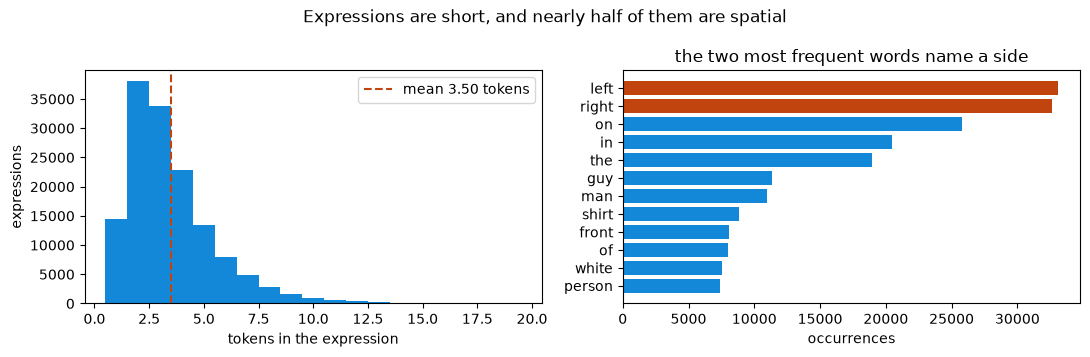

In [6]:
lengths = [len(s["tokens"]) for s in expressions]
tokens = [t for s in expressions for t in s["tokens"]]
frequency = collections.Counter(tokens)
SPATIAL = {"left", "right", "leftmost", "rightmost"}
spatial = sum(1 for s in expressions if SPATIAL & set(s["tokens"]))

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
left.hist(lengths, bins=range(1, 21), color=COLOURS[0], align="left")
left.axvline(np.mean(lengths), color=COLOURS[2], linestyle="--",
             label=f"mean {np.mean(lengths):.2f} tokens")
left.set_xlabel("tokens in the expression")
left.set_ylabel("expressions")
left.legend()
words, values = zip(*frequency.most_common(12))
right.barh(range(len(words))[::-1], values,
           color=[COLOURS[2] if w in SPATIAL else COLOURS[0] for w in words])
right.set_yticks(range(len(words))[::-1], words)
right.set_xlabel("occurrences")
right.set_title("the two most frequent words name a side")
fig.suptitle("Expressions are short, and nearly half of them are spatial")
save(fig, EDA / "expressions", close=False)
print(f"{spatial:,} of {len(expressions):,} expressions name a side = {spatial/len(expressions):.1%}")
print(f"vocabulary {len(frequency):,} types over {len(tokens):,} tokens")

At 3.50 tokens a sequence encoder has little to carry, so how its output is attached matters
more than which encoder it is. Because 46.3% of expressions name a side, a horizontal flip must
rewrite the words it inverts or it relabels nearly half the training data; the loader does this,
and the ablation can switch it off.

## Spatial language and target position

If side words are reliable, a model that reads only the expression is not guessing: it can place
the target horizontally. That sets the floor for the modality-B baseline.

says left   mean x 0.258   says right  mean x 0.742
names a side: 31,261 objects = 62.5%, agreeing 96.2%


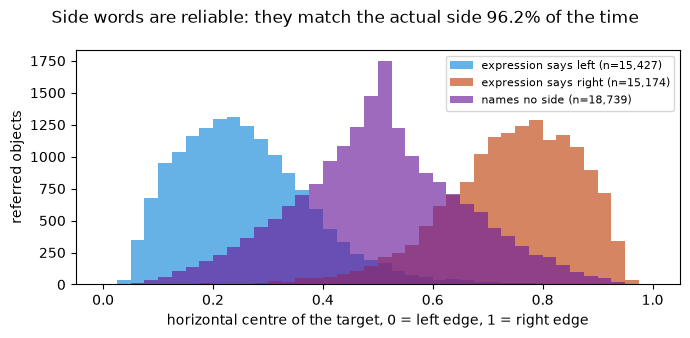

In [7]:
position = []
for r in refs:
    box, info = annotations[r["ann_id"]]["bbox"], images[r["image_id"]]
    centre = (box[0] + box[2] / 2) / info["width"]
    words = {t for s in r["sentences"] for t in s["tokens"]}
    position.append((centre, bool({"left", "leftmost"} & words), bool({"right", "rightmost"} & words)))

says_left = [c for c, l, r_ in position if l and not r_]
says_right = [c for c, l, r_ in position if r_ and not l]
says_neither = [c for c, l, r_ in position if not l and not r_]
named = [p for p in position if p[1] or p[2]]
agree = sum(1 for c, l, r_ in named if (l and c < 0.5) or (r_ and c >= 0.5)) / len(named)

fig, axis = plt.subplots(figsize=(7, 3.4))
for values, label, colour in ((says_left, "expression says left", COLOURS[0]),
                              (says_right, "expression says right", COLOURS[2]),
                              (says_neither, "names no side", COLOURS[4])):
    axis.hist(values, bins=40, range=(0, 1), alpha=0.65, label=f"{label} (n={len(values):,})",
              color=colour)
axis.set_xlabel("horizontal centre of the target, 0 = left edge, 1 = right edge")
axis.set_ylabel("referred objects")
axis.legend(fontsize=8)
fig.suptitle(f"Side words are reliable: they match the actual side {agree:.1%} of the time")
save(fig, EDA / "position", close=False)
print(f'says left   mean x {np.mean(says_left):.3f}   says right  mean x {np.mean(says_right):.3f}')
print(f'names a side: {len(named):,} objects = {len(named)/len(refs):.1%}, agreeing {agree:.1%}')

For the 62.5% of objects whose expression names a side, language alone places the target on the
correct half 96.2% of the time. The text-only baseline is therefore a real spatial prior rather
than a formality, though it still cannot say which instance on that side. That remainder is what
the fusion has to recover.

## Category mentions

In [8]:
named_category = 0
for r in refs:
    words = categories[r["category_id"]].lower().split()
    if any(any(w in s["tokens"] for w in words) for s in r["sentences"]):
        named_category += 1
print(f"{named_category:,} of {len(refs):,} objects = {named_category/len(refs):.1%} "
      f"have an expression containing their category name")

25,858 of 50,000 objects = 51.7% have an expression containing their category name


Half the time the expression states the category, so the text selects it and the image narrows
within it. The other half gives no category word, leaving the fusion to ground an attribute or a
position against whatever the vision branch found. A model that only matched category names would
stall near half the data.

## Vocabulary coverage and ambiguity

val    OOV tokens  1.93%   expressions with one   6.2%
testA  OOV tokens  1.59%   expressions with one   5.1%
testB  OOV tokens  2.27%   expressions with one   7.5%

ambiguous: 150 of 142,210 = 0.11% name more than one object


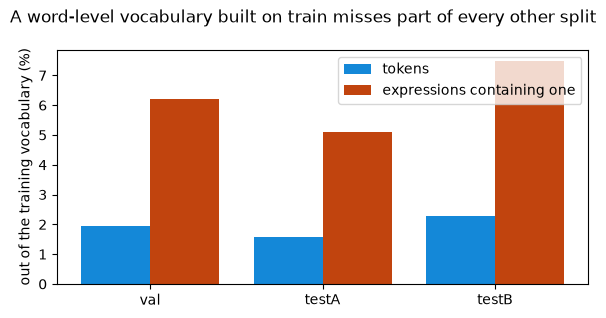

In [9]:
vocabulary = build_vocabulary(refs)
coverage = {}
for name in ("val", "testA", "testB"):
    sentences = [s for r in refs if r["split"] == name for s in r["sentences"]]
    here = [t for s in sentences for t in s["tokens"]]
    coverage[name] = {
        "oov_tokens": sum(1 for t in here if t not in vocabulary) / len(here),
        "expressions_with_oov": sum(
            1 for s in sentences if any(t not in vocabulary for t in s["tokens"])) / len(sentences),
    }

by_image = collections.defaultdict(list)
for r in refs:
    for s in r["sentences"]:
        by_image[r["image_id"]].append((s["sent"].strip().lower(), r["ann_id"]))
ambiguous = total = 0
for entries in by_image.values():
    targets = collections.defaultdict(set)
    for text, ann in entries:
        targets[text].add(ann)
    total += len(entries)
    ambiguous += sum(len(v) for v in targets.values() if len(v) > 1)

fig, axis = plt.subplots(figsize=(6, 3.2))
names = list(coverage)
axis.bar([i - 0.2 for i in range(len(names))],
         [coverage[n]["oov_tokens"] * 100 for n in names], width=0.4, label="tokens", color=COLOURS[0])
axis.bar([i + 0.2 for i in range(len(names))],
         [coverage[n]["expressions_with_oov"] * 100 for n in names], width=0.4,
         label="expressions containing one", color=COLOURS[2])
axis.set_xticks(range(len(names)), names)
axis.set_ylabel("out of the training vocabulary (%)")
axis.legend()
fig.suptitle("A word-level vocabulary built on train misses part of every other split")
save(fig, EDA / "vocabulary", close=False)
for name in names:
    print(f"{name:<6} OOV tokens {coverage[name]['oov_tokens']:>6.2%}   "
          f"expressions with one {coverage[name]['expressions_with_oov']:>6.1%}")
print(f"\nambiguous: {ambiguous:,} of {total:,} = {ambiguous/total:.2%} name more than one object")

A word-level vocabulary fitted on train leaves 5.1% to 7.5% of test expressions carrying an
unknown token, and in a three-token expression one unknown word is most of the signal. A
pretrained subword tokenizer has no such gap, which is why the text branch starts from pretrained
weights rather than an embedding table fitted here.

Only 0.11% of expressions name more than one object in their own image, so the task is well posed
even though an independent review judged 14% of RefCOCO annotations imperfect.

## Target size and category

objects under 1% of the frame: 0.0%


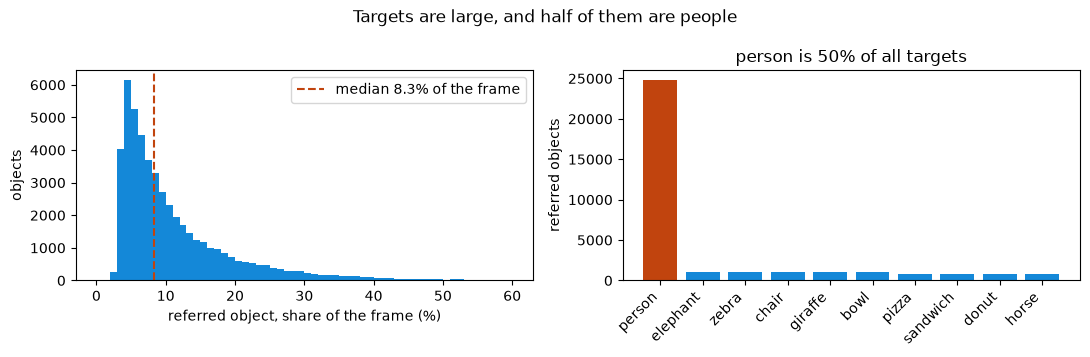

In [10]:
areas = sorted(annotations[r["ann_id"]]["area"] /
               (images[r["image_id"]]["width"] * images[r["image_id"]]["height"]) for r in refs)
category_counts = collections.Counter(categories[r["category_id"]] for r in refs)

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
left.hist([a * 100 for a in areas], bins=60, range=(0, 60), color=COLOURS[0])
left.axvline(np.median(areas) * 100, color=COLOURS[2], linestyle="--",
             label=f"median {np.median(areas):.1%} of the frame")
left.set_xlabel("referred object, share of the frame (%)")
left.set_ylabel("objects")
left.legend()
names, values = zip(*category_counts.most_common(10))
right.bar(range(len(names)), values, color=[COLOURS[2]] + [COLOURS[0]] * (len(names) - 1))
right.set_xticks(range(len(names)), names, rotation=45, ha="right")
right.set_ylabel("referred objects")
right.set_title(f"person is {category_counts['person']/len(refs):.0%} of all targets")
fig.suptitle("Targets are large, and half of them are people")
save(fig, EDA / "targets", close=False)
print(f"objects under 1% of the frame: {sum(1 for a in areas if a < 0.01)/len(areas):.1%}")

Not one of the 50,000 targets falls below 1% of its frame, so boundary precision is not the
binding constraint. The difficulty is selecting the right instance, not sharpening its edge.

## Mask and image geometry

polygons per mask: mean 1.14, max 23
stored as RLE rather than polygon: 0; iscrowd: 0
distinct resolutions: 1,052; aspect ratio median 1.33


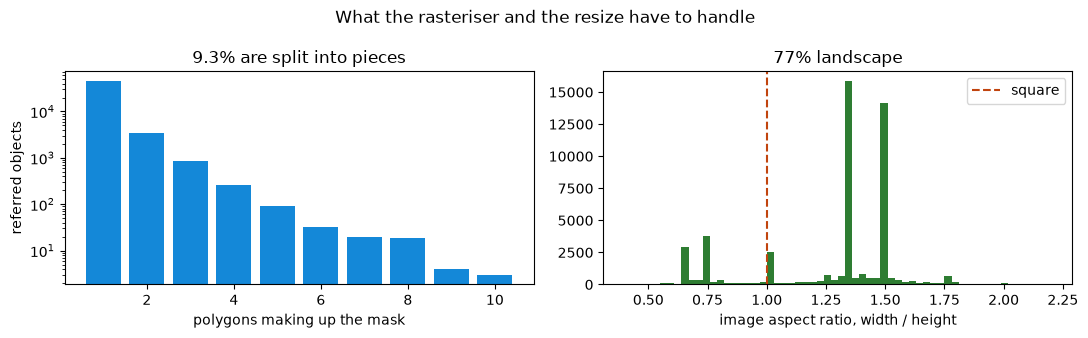

In [11]:
polygons = [len(annotations[r["ann_id"]]["segmentation"])
            if isinstance(annotations[r["ann_id"]]["segmentation"], list) else 0 for r in refs]
shapes = [(images[r["image_id"]]["width"], images[r["image_id"]]["height"]) for r in refs]
ratios = [w / h for w, h in shapes]

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.4))
counts = collections.Counter(polygons)
keys = sorted(counts)[:10]
left.bar(keys, [counts[k] for k in keys], color=COLOURS[0])
left.set_xlabel("polygons making up the mask")
left.set_ylabel("referred objects")
left.set_yscale("log")
left.set_title(f"{sum(1 for p in polygons if p > 1)/len(polygons):.1%} are split into pieces")
right.hist(ratios, bins=60, range=(0.4, 2.2), color=COLOURS[3])
right.axvline(1.0, color=COLOURS[2], linestyle="--", label="square")
right.set_xlabel("image aspect ratio, width / height")
right.legend()
right.set_title(f"{sum(1 for a in ratios if a > 1)/len(ratios):.0%} landscape")
fig.suptitle("What the rasteriser and the resize have to handle")
save(fig, EDA / "shapes", close=False)
print(f"polygons per mask: mean {np.mean(polygons):.2f}, max {max(polygons)}")
print(f"stored as RLE rather than polygon: {sum(1 for p in polygons if p == 0)}; "
      f"iscrowd: {sum(1 for r in refs if annotations[r['ann_id']].get('iscrowd'))}")
print(f"distinct resolutions: {len(set(shapes)):,}; aspect ratio median {np.median(ratios):.2f}")

9.3% of targets are several polygons, one object seen around an occluder, and one reaches 23
pieces. Keeping only the largest connected component would discard part of the answer for one
target in eleven, so the prediction stays the raw per-pixel argmax. Nothing is run-length encoded
and nothing is marked as a crowd, so the rasteriser handles polygons alone. 77% of images are
landscape, so resizing to a square stretches most of them; padding instead would spend the budget
on background.

## Normalization and the preprocessed batch

In [12]:
random.seed(0)
sample = random.sample(sorted({r["image_id"] for r in refs if r["split"] == "train"}), 300)
total_sum = np.zeros(3)
total_square = np.zeros(3)
pixels = 0
for image_id in sample:
    array = np.asarray(Image.open(IMAGE_DIR / images[image_id]["file_name"]).convert("RGB"),
                       dtype=np.float64) / 255
    flat = array.reshape(-1, 3)
    total_sum += flat.sum(0)
    total_square += (flat ** 2).sum(0)
    pixels += flat.shape[0]
mean = total_sum / pixels
std = np.sqrt(total_square / pixels - mean ** 2)
print(f"measured over 300 training images: mean {np.round(mean, 3).tolist()}  "
      f"std {np.round(std, 3).tolist()}")
print("ImageNet, which the pretrained weights expect: mean [0.485, 0.456, 0.406]  "
      "std [0.229, 0.224, 0.225]")

measured over 300 training images: mean [0.466, 0.421, 0.372]  std [0.284, 0.276, 0.283]
ImageNet, which the pretrained weights expect: mean [0.485, 0.456, 0.406]  std [0.229, 0.224, 0.225]


In [13]:
from src.data import build_dataloaders

loaders = build_dataloaders({**config, "loader": {**config["loader"], "num_workers": 0}})
batch = next(iter(loaders["val"]))
for key, value in batch.items():
    print(f"{key:<10} {tuple(value.shape)} {value.dtype}")
print(f"\nimages span [{batch['images'].min():.3f}, {batch['images'].max():.3f}]")
print(f"mask values {sorted(set(batch['masks'].unique().tolist()))}, "
      f"foreground {batch['masks'].float().mean():.1%} of pixels")
print(f"real tokens per row {batch['attention'].sum(1).tolist()}")

images     (8, 3, 320, 320) torch.float32
tokens     (8, 8) torch.int64
attention  (8, 8) torch.bool
masks      (8, 320, 320) torch.int64
ref_ids    (8,) torch.int64

images span [-2.118, 2.413]
mask values [0, 1], foreground 22.6% of pixels
real tokens per row [8, 5, 7, 5, 5, 3, 3, 1]


These statistics are close to ImageNet in the mean but wider in the spread, 0.28 against 0.23.
The loader applies the ImageNet values regardless, because they are what the pretrained vision
weights were fitted under, and a differently normalised batch degrades a pretrained backbone
silently. The measured values are recorded so the choice is visible rather than assumed.

## Qualitative examples

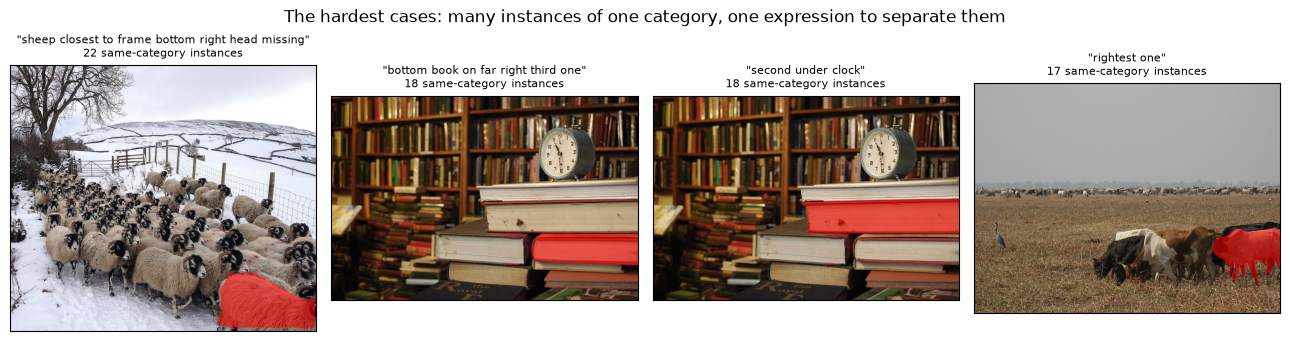

In [14]:
def overlay(ref, axis, note=""):
    info = images[ref["image_id"]]
    picture = Image.open(IMAGE_DIR / info["file_name"]).convert("RGB")
    rles = mask_utils.frPyObjects(annotations[ref["ann_id"]]["segmentation"],
                                  info["height"], info["width"])
    mask = mask_utils.decode(mask_utils.merge(rles))
    axis.imshow(picture)
    axis.imshow(np.ma.masked_where(mask == 0, mask), cmap="autumn", alpha=0.55)
    axis.set_title(f'"{ref["sentences"][0]["sent"]}"\n{note}', fontsize=8)
    axis.set_xticks([]); axis.set_yticks([])

crowded = sorted(zip(distractors, range(len(refs))), key=lambda p: -p[0])[:4]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for (count, index), axis in zip(crowded, axes):
    overlay(refs[index], axis, f"{count} same-category instances")
fig.suptitle("The hardest cases: many instances of one category, one expression to separate them")
save(fig, EDA / "examples", close=False)

## Findings

Seven measurements shape the design.

| Measurement | Consequence |
| --- | --- |
| No target is alone in its category; 4.90 distractors on average | A model that never reads the text cannot exceed 30.5% |
| Side words agree with the real side 96.2% of the time, for 62.5% of targets | The text-only baseline is a genuine spatial prior, not a formality |
| 51.7% of objects have an expression naming their category | Half the task is category selection, half is grounding within one |
| Expressions average 3.50 tokens; 5.1–7.5% of test expressions hold an unseen word | A pretrained subword tokenizer, not a vocabulary fitted here |
| 46.3% of expressions name a side | A horizontal flip must rewrite the words it inverts |
| No target is smaller than 1% of its frame | Instance selection matters, boundary precision does not |
| 9.3% of masks are several polygons | No largest-component post-processing |

The fusion follows from the first three rows. Neither modality is sufficient: the image locates
instances but cannot choose among them, and the language chooses a side and often a category but
cannot outline anything. Pooling the sentence into one vector, as the simple baseline does, can
express *which half* and *which category*; it cannot express *which of those three people*.
Cross-attention can, and that is the hypothesis the ablation tests.

In [15]:
summary = {
    "pairs": len(expressions),
    "objects": len(refs),
    "images": len(images),
    "missing_modality_rate": {k: v / len(refs) for k, v in missing.items()},
    "distractors_mean": float(np.mean(distractors)),
    "blind_guess_ceiling": ceiling,
    "side_word_agreement": agree,
    "names_a_side_rate": len(named) / len(refs),
    "names_category_rate": named_category / len(refs),
    "spatial_expression_rate": spatial / len(expressions),
    "tokens_mean": float(np.mean(lengths)),
    "vocabulary": len(frequency),
    "oov": coverage,
    "ambiguous_expression_rate": ambiguous / total,
    "target_area_median": float(np.median(areas)),
    "multi_polygon_rate": sum(1 for p in polygons if p > 1) / len(polygons),
    "landscape_rate": sum(1 for a in ratios if a > 1) / len(ratios),
    "person_share_by_split": split_person,
    "measured_normalization": {"mean": mean.tolist(), "std": std.tolist()},
    "annotation_error_rate_external": 3054 / 21586,
}
shared_io.write_json(EDA / "findings.json", summary)
print(f"{len(summary)} findings written to results/eda/findings.json")

20 findings written to results/eda/findings.json
